# Article A, notebook 1: ramified transport, closed forms, and the exact solver

This notebook replicates Sections 2 and 4.1 of *Topology Persistence under Target Insertion in Ramified Optimal Transport* and the checks of the exact solver in Appendix A: the cost functional, the full topologies, the geometry of a fixed topology, the exact solver with tied optimal topologies, the closed forms for one and two targets, the six targets on a circle of Remark 2.4, and the cost of the solver. Figures 1, 2, and 3 of the paper are rebuilt from the results stored in `figures/`.

Notebook 2 covers the inductive step of Section 3, the ladders, the certificate, and batch insertion; notebook 3 covers the vaccine network from Pune.

**How to run.** Open the notebook in Google Colab and choose *Runtime > Run all*; there is nothing to upload, mount, or find. The first code cell unpacks the code and data embedded in the notebook (nine files, 1 MB: the library `rot_core.py`, `rot_tools.py`, and `plotstyle.py` in `colab/`, and the stored results and reference figures in `figures/`) into the folder `/content/ArticleA` and makes it the working directory; every path named below, such as `figures/` or `colab/output/`, is inside that folder. Outside Colab, in Jupyter or VS Code, the same cell writes the folder `ArticleA_runtime` next to the notebook. No GPU and no paid service are needed, and the notebook uses no external data.

**Default run and full run.** Each computation prints `PASS` or `FAIL` against the numbers of the paper or the stored results, and the last cell counts the checks. The default run took about one and a half minutes on the laptop used for the paper; a free Colab session, with two slower cores, takes a few minutes more. Setting `RUN_FULL = True` in the cell after the setup recomputes the one result that the default run takes from storage:

| Section | Default run | `RUN_FULL = True` |
|---|---|---|
| 1 to 5 | everything (the 140 symmetric pairs and 400 triangles of Appendix A included) | the same |
| 6 | exact solutions at $\alpha=0.75$ and $0.8$, compared with the stored ones; Figure 2 from storage | all five values of $\alpha$ (one to three minutes per value on one core) |
| 7 | Figure 3 from the stored timings; a fresh timing from three to five terminals | the same |

The code is in three files: `rot_core.py` (geometry solver and exact enumeration), `rot_tools.py` (instances, insertion steps, certificate, tables, figures), and `plotstyle.py` (figure style).

## 0. Setup

In [1]:
# @title Unpack the code and data embedded in this notebook
# Nothing has to be uploaded, mounted, or found. PAYLOAD, at the end of this cell, is a zip archive in base64 of the
# files this notebook reads, with their paths in the folder ArticleA of the paper. The cell writes them to a working
# folder, /content/ArticleA in Google Colab and ArticleA_runtime next to the notebook elsewhere, puts that folder and
# its subfolders colab/ and code/ on sys.path, makes it the working directory, and lists what it wrote.
import base64, importlib.util, io, os, sys, zipfile


def running_in_colab():
    """True in Google Colab, where the folder /content exists and the module google.colab is available."""
    if not os.path.isdir("/content"):
        return False
    if "google.colab" in sys.modules:
        return True
    try:
        return importlib.util.find_spec("google.colab") is not None
    except (ImportError, ValueError):
        return False


def same_content(path, data):
    """True when the file at path exists and holds exactly data."""
    if not os.path.isfile(path) or os.path.getsize(path) != len(data):
        return False
    with open(path, "rb") as f:
        return f.read() == data


def unpack(payload):
    """Extract the embedded archive into the working folder and enter it; returns the folder and whether it is Colab."""
    in_colab = running_in_colab()
    if in_colab:
        root = "/content/ArticleA"
    else:
        here = os.getcwd()                  # Jupyter and VS Code start the kernel in the folder of the notebook
        root = here if os.path.basename(here) == "ArticleA_runtime" else os.path.join(here, "ArticleA_runtime")
    listing = []
    with zipfile.ZipFile(io.BytesIO(base64.b64decode(payload))) as z:
        for info in z.infolist():
            parts = info.filename.split("/")
            if info.is_dir() or info.filename.startswith("/") or ".." in parts:
                continue
            data = z.read(info)             # checks the CRC of the entry
            target = os.path.join(root, *parts)
            os.makedirs(os.path.dirname(target), exist_ok=True)
            if not same_content(target, data):
                with open(target + ".part", "wb") as f:      # a whole file or none, also when two notebooks
                    f.write(data)                            # unpack into the same folder at the same time
                os.replace(target + ".part", target)
            listing.append((info.filename, len(data)))
    for sub in ("", "code", "colab"):       # in the end colab/ comes first on sys.path, then code/, then the folder
        folder = os.path.join(root, sub) if sub else root
        if os.path.isdir(folder) and folder not in sys.path:
            sys.path.insert(0, folder)
    os.chdir(root)
    where = root if in_colab else "ArticleA_runtime, next to this notebook"
    print(f"unpacked {len(listing)} files, {sum(n for _, n in listing) / 1e6:.1f} MB, into {where}:")
    for folder in sorted({os.path.dirname(name) for name, _ in listing}):
        names = [os.path.basename(name) for name, _ in listing if os.path.dirname(name) == folder]
        print(f"  {folder}/: {', '.join(names)}")
    return root, in_colab

PAYLOAD = """
...
"""
ROOT, IN_COLAB = unpack(PAYLOAD)

unpacked 9 files, 1.0 MB, into /content/ArticleA:
  colab/: plotstyle.py, rot_core.py, rot_tools.py
  figures/: exact_solver_timing.json, fig_exact_scaling.png, fig_threshold_angle.png, fig_xia_circle_n6.png, scaling_measurements.json
  figures/theory/: xia_circle_n6.json


In [2]:
# Setup: the same cell works in Google Colab and locally. ROOT is the working folder written by the cell above.
import os, sys, importlib.util, subprocess
for var in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(var, "1")            # one BLAS thread per process; the long loops use processes instead

if IN_COLAB:
    # Latin Modern gives the figures the face of the manuscript; without it they use matplotlib's Computer Modern
    subprocess.run("apt-get -qq install fonts-lmodern > /dev/null 2>&1", shell=True)

# pip installs only what is missing (Colab already has all of these)
missing = [p for p in ("numpy", "scipy", "matplotlib", "pandas", "sympy") if importlib.util.find_spec(p) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)

COLAB_DIR = os.path.join(ROOT, "colab")       # rot_core.py, rot_tools.py, plotstyle.py
FIG = os.path.join(ROOT, "figures")            # stored results of the paper
TABLES = os.path.join(ROOT, "overleaf_A", "tables")
OUT = os.path.join(COLAB_DIR, "output")        # everything this notebook writes
for sub in ("figures", "tables", "results"):
    os.makedirs(os.path.join(OUT, sub), exist_ok=True)
print("folder", os.path.basename(ROOT), "| Colab" if IN_COLAB else "| local", "| cores:", os.cpu_count())

folder ArticleA | Colab | cores: 2


In [3]:
RUN_FULL = False      # True recomputes the stored solutions of Section 6 (see the table above)

import filecmp, json, time
import numpy as np
from IPython.display import Image, display
import rot_core as RC       # geometry of a fixed topology, enumeration of full topologies, exact solver
import rot_tools as RT      # instances, restriction, insertion steps, certificate, tables, figures
ck = RT.Checker()           # collects the PASS/FAIL lines of this notebook
T_START = time.perf_counter()

## 1. Transport paths and their cost (Section 2.1)

The source is a single point $O$ that carries the total mass, and the targets $y_1,\dots,y_n$ carry the masses $m_1,\dots,m_n$:

$$\mathbf a = m\,\delta_O,\qquad \mathbf b=\sum_{i=1}^{n} m_i\,\delta_{y_i},\qquad m=\sum_{i=1}^{n} m_i .$$

A transport path from $\mathbf a$ to $\mathbf b$ is a weighted directed graph $G$ whose net outflow at $O$ is $m$, whose net inflow at $y_i$ is $m_i$, and which conserves the flow at every other vertex. For $\alpha\in[0,1]$ its cost is

$$\mathbf M_\alpha(G)=\sum_{e\in E(G)}|e|\,w(e)^{\alpha},$$

and $d_\alpha(\mathbf a,\mathbf b)$ is the least cost over all transport paths. For $\alpha<1$ the map $w\mapsto w^{\alpha}$ is subadditive, $(w_1+w_2)^{\alpha}<w_1^{\alpha}+w_2^{\alpha}$, so two loads that share a stretch pay less than the same loads apart, and optimal paths branch. At $\alpha=1$ the star of straight segments is optimal (the Monge-Kantorovich case); at $\alpha=0$ the cost is the length of the tree (the Euclidean Steiner problem).

The textbook instance has $O=(0,-1)$ and two unit targets at $(\pm1,1)$. A Y-shaped path with its branching point at $B=(0,t)$ costs

$$M(t)=2^{\alpha}\,(t+1)+2\sqrt{1+(1-t)^{2}},\qquad -1\le t\le 1,$$

and $t=-1$ is the star (the V), of cost $2\sqrt5$. By symmetry and convexity the optimum has its branching point on the axis, so the least value of $M(t)$ must equal the cost returned by the exact solver.

In [4]:
from scipy.optimize import minimize_scalar

s, T, m = RC.instance_y()                     # O = (0, -1), targets (-1, 1) and (1, 1), unit masses
for alpha in (0.25, 0.5, 0.75, 0.95):
    M = lambda t: 2 ** alpha * (t + 1) + 2 * np.hypot(1.0, 1.0 - t)        # cost of the Y with B = (0, t)
    t_best = minimize_scalar(M, bounds=(-1.0, 1.0), method="bounded", options={"xatol": 1e-12}).x
    y_best = min(M(t_best), M(-1.0))                                       # t = -1 is the star
    star = RC.v_shape_cost(s, T, m, alpha)                                 # 2 sqrt(5) at every alpha
    exact, topo, P = RC.solve_exhaustive(RC.terminals_of(s, T), m, alpha)
    print(f"alpha = {alpha}: star {star:.8f}, best Y {y_best:.8f} (t = {t_best:+.5f}), exact solver {exact:.8f}")
    ck(f"exact solver equals the best Y, alpha = {alpha}", abs(exact - y_best) <= 1e-8 * exact)

alpha = 0.25: star 4.47213595, best Y 3.98645230 (t = +0.26046), exact solver 3.98645230
PASS  exact solver equals the best Y, alpha = 0.25
alpha = 0.5: star 4.47213595, best Y 4.24264069 (t = +0.00000), exact solver 4.24264069
PASS  exact solver equals the best Y, alpha = 0.5
alpha = 0.75: star 4.47213595, best Y 4.44597786 (t = -0.55377), exact solver 4.44597786
PASS  exact solver equals the best Y, alpha = 0.75
alpha = 0.95: star 4.47213595, best Y 4.47213595 (t = -1.00000), exact solver 4.47213595
PASS  exact solver equals the best Y, alpha = 0.95


## 2. Full topologies (Section 2.2)

A full topology on the $k=n+1$ terminals is a tree in which every terminal has degree one and the other $k-2$ vertices, the branching points, have degree three. Its edge flows are fixed by the masses: an edge carries the mass of the targets it separates from the source. Writing $c(T)=\min_P \mathbf M_\alpha(T,P)$ for the cost of a topology $T$ with its branching points $P$ placed optimally,

$$d_\alpha(\mathbf a,\mathbf b)=\min_T c(T),$$

the minimum over the $(2k-5)!!$ full topologies. Inserting terminal $j\ge3$ on every edge of every tree on the terminals $0,\dots,j-1$ generates each of them exactly once. A topology is identified by its splits, the sets of targets that its edges separate from the source; `RT.canon` returns them as bitmasks.

In [5]:
from math import prod

for k in range(3, 9):
    topologies = list(RC.enumerate_full_topologies(k))
    double_factorial = prod(range(2 * k - 5, 0, -2))                  # (2k-5)!!
    distinct = len({RT.canon(t.edges, k) for t in topologies})       # told apart by their splits
    print(f"k = {k}: generated {len(topologies):6d}, (2k-5)!! = {double_factorial:6d}, distinct {distinct:6d}")
    ck(f"each of the (2k-5)!! full topologies generated once, k = {k}",
       len(topologies) == double_factorial == distinct == RC.count_full_topologies(k))

# edge flows of one topology on four terminals: node 0 is the source, 1-3 the targets, 4-5 the branching points
topo = next(RC.enumerate_full_topologies(4))
masses = np.array([1.0, 2.0, 0.5])
flows = RC.edge_flows(topo, masses)
for (u, v), w in flows.items():
    print(f"edge {u}-{v}: flow {w}")
ck("the edge at the source carries the total mass", max(flows.values()) == masses.sum())

k = 3: generated      1, (2k-5)!! =      1, distinct      1
PASS  each of the (2k-5)!! full topologies generated once, k = 3
k = 4: generated      3, (2k-5)!! =      3, distinct      3
PASS  each of the (2k-5)!! full topologies generated once, k = 4
k = 5: generated     15, (2k-5)!! =     15, distinct     15
PASS  each of the (2k-5)!! full topologies generated once, k = 5
k = 6: generated    105, (2k-5)!! =    105, distinct    105
PASS  each of the (2k-5)!! full topologies generated once, k = 6
k = 7: generated    945, (2k-5)!! =    945, distinct    945
PASS  each of the (2k-5)!! full topologies generated once, k = 7
k = 8: generated  10395, (2k-5)!! =  10395, distinct  10395
PASS  each of the (2k-5)!! full topologies generated once, k = 8
edge 1-4: flow 1.0
edge 2-4: flow 2.0
edge 0-5: flow 3.5
edge 4-5: flow 3.0
edge 3-5: flow 0.5
PASS  the edge at the source carries the total mass


## 3. Geometry of a fixed topology (Section 2.2 and Remark 2.3)

For a fixed $T$ the map $P\mapsto\mathbf M_\alpha(T,P)$ is convex, since each term is a positive multiple of the norm of an affine function of $P$. The Weiszfeld step moves a branching point $s$ to the weighted mean of its neighbors,

$$P_s^{(t+1)}=\frac{\sum_{e=(s,v)} w(e)^{\alpha}\,P_v^{(t)}/|e^{(t)}|}{\sum_{e=(s,v)} w(e)^{\alpha}/|e^{(t)}|},$$

and the code moves all branching points at once (the Jacobi form of iteratively reweighted least squares). It works in coordinates centered at the centroid of the terminals and scaled by their diameter, so that every tolerance is relative. The *scan* is a short run of at most 300 sweeps from the centroid. The *polish* continues with 1000 sweeps, minimizes the cost with each norm smoothed to $\sqrt{|x|^2+\delta}$ for $\delta=10^{-8},10^{-12},10^{-15}$ by L-BFGS, and merges a branching point with any node closer than $5\times10^{-3}$ diameters whenever the merge lowers the exact cost.

Remark 2.3 is the reason for the polish: where a branching point of the optimum coincides with another node the cost is not differentiable, the iteration slows down, and a scan can rank a topology well above its true cost. The cell below scans and polishes all 105 topologies of a five-target instance of the disk-center family at $\alpha=0.85$ (about 15 seconds).

In [6]:
s, T, m = RT.make_instance("disk-center", 0)
T, m, alpha = T[:5], m[:5], 0.85
term = RC.terminals_of(s, T)
topologies = list(RC.enumerate_full_topologies(len(term)))
scan, polished, positions = [], [], []
for topo in topologies:
    c0, P0 = RC.optimize_geometry(topo, term, m, alpha)                       # scan: 300 sweeps from the centroid
    c1, P1 = RC.optimize_geometry(topo, term, m, alpha, iters=1000, tol=1e-13, polish=True, P0=P0)
    scan.append(c0)
    polished.append(c1)
    positions.append(P1)
scan, polished = np.array(scan), np.array(polished)
excess = scan / polished - 1
best = int(np.argmin(polished))
rank_in_scan = int(np.argsort(np.argsort(scan))[best])
nondeg_best = RT.nondegenerate_branching_points(topologies[best], positions[best])
print(f"largest excess of a scan over its polished cost: {100 * excess.max():.2f} percent (topology {int(np.argmax(excess))})")
print(f"the optimal topology ({best}) has {nondeg_best} of {len(T) - 1} branching points away from the other nodes;"
      f" the scan ranks it {rank_in_scan + 1} of 105, and the best scan cost is"
      f" {100 * (scan.min() / polished.min() - 1):.2f} percent above the optimum")
ck("the polish never ends above the scan", np.all(polished <= scan * (1 + 1e-12)))
ck("the optimum of this instance is degenerate and the scan misranks it (Remark 2.3)",
   nondeg_best < len(T) - 1 and rank_in_scan > 0)

largest excess of a scan over its polished cost: 9.69 percent (topology 81)
the optimal topology (70) has 1 of 4 branching points away from the other nodes; the scan ranks it 18 of 105, and the best scan cost is 3.46 percent above the optimum
PASS  the polish never ends above the scan
PASS  the optimum of this instance is degenerate and the scan misranks it (Remark 2.3)


The cell below writes the Jacobi step out in full and runs it from the centroid on the optimal topology of the same five targets at two exponents. At $\alpha=0.5$ three of the four branching points of the optimum are away from the other nodes, and the iteration reaches the optimal cost to rounding within a few hundred sweeps; at $\alpha=0.85$ three of them coincide with other nodes, and after 3000 sweeps the iteration is still about two percent above the optimum.

alpha = 0.5: excess over the optimum after 10, 100, 1000, 3000 sweeps: 2.3e-01, 1.2e-06, 9.1e-15, 9.1e-15
alpha = 0.85: excess over the optimum after 10, 100, 1000, 3000 sweeps: 1.2e-01, 7.5e-02, 4.8e-02, 2.3e-02
PASS  the Jacobi step reaches the nondegenerate optimum and stalls at the degenerate one


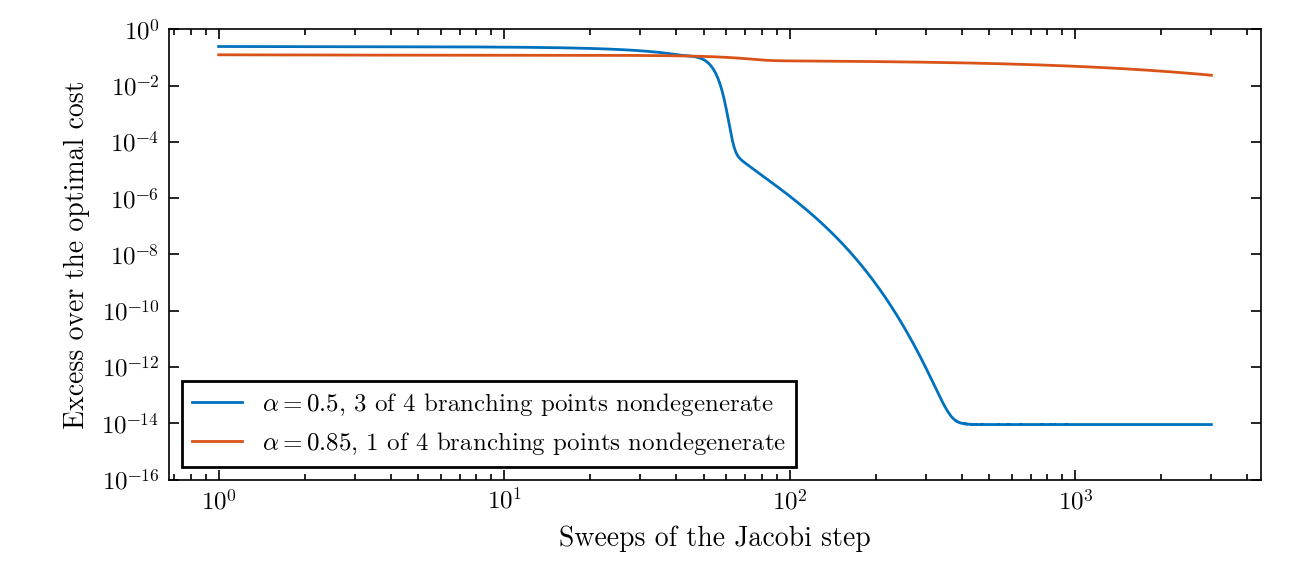

In [7]:
import matplotlib.pyplot as plt
import plotstyle as ps

def irls_history(topo, term, m, alpha, sweeps=3000):
    """Plain Jacobi IRLS from the centroid (unscaled coordinates); the cost after every sweep."""
    k = topo.k
    w = {e: f ** alpha for e, f in RC.edge_flows(topo, m).items()}          # w(e)^alpha on every edge
    E, W = np.array(list(w)), np.array(list(w.values()))
    P = np.zeros((2 * k - 2, 2))
    P[:k] = term
    P[k:] = term.mean(axis=0) + 1e-3 * np.random.default_rng(0).standard_normal((k - 2, 2))
    history = []
    for _ in range(sweeps):
        L = np.maximum(np.hypot(*(P[E[:, 0]] - P[E[:, 1]]).T), 1e-14)       # edge lengths |e|
        history.append(float((W * L).sum()))
        c = W / L                                                          # weights w(e)^alpha / |e|
        num = np.zeros_like(P)
        den = np.zeros(len(P))
        np.add.at(num, E[:, 0], c[:, None] * P[E[:, 1]])
        np.add.at(num, E[:, 1], c[:, None] * P[E[:, 0]])
        np.add.at(den, E[:, 0], c)
        np.add.at(den, E[:, 1], c)
        P[k:] = num[k:] / den[k:, None]                                    # every branching point moves at once
    return np.array(history), P

# the optimal topology of the same five targets at alpha = 0.5 (exact solver) and at alpha = 0.85 (found above)
c05, topo05, P05 = RC.solve_exhaustive(term, m, 0.5)
cases = [(0.5, topo05, c05, RT.nondegenerate_branching_points(topo05, P05)),
         (0.85, topologies[best], polished[best], nondeg_best)]
size = ps.apply(textwidth_in=6.5, aspect=0.45)
fig, ax = plt.subplots(figsize=size)
excess_end = {}
for (a_, topo_, c_opt, nd), color in zip(cases, ps.MATLAB_COLORS):
    h, P = irls_history(topo_, term, m, a_)
    label = rf"$\alpha = {a_}$, {nd} of {len(T) - 1} branching points nondegenerate"
    ax.loglog(np.arange(1, len(h) + 1), np.maximum(h / c_opt - 1, 1e-16), "-", color=color, label=label)
    excess_end[a_] = h[-1] / c_opt - 1
    print(f"alpha = {a_}: excess over the optimum after 10, 100, 1000, 3000 sweeps:",
          ", ".join(f"{h[j] / c_opt - 1:.1e}" for j in (9, 99, 999, len(h) - 1)))
ck("the Jacobi step reaches the nondegenerate optimum and stalls at the degenerate one",
   excess_end[0.5] < 1e-12 and excess_end[0.85] > 1e-2)
ax.set_ylim(1e-16, 1)
ps.finish(ax, xlabel="Sweeps of the Jacobi step", ylabel="Excess over the optimal cost")
ax.legend(loc="lower left")
fig.subplots_adjust(left=0.13, right=0.97, bottom=0.18, top=0.95)
fig.savefig(os.path.join(OUT, "figures", "irls_convergence.png"), dpi=200)
plt.close(fig)
display(Image(os.path.join(OUT, "figures", "irls_convergence.png"), width=700))

## 4. The exact solver and tied optimal topologies (Section 4.1, Algorithm 1)

`RC.solve_exhaustive` scans every full topology, polishes all of them up to seven terminals (above that, those within 25 percent of the best scan cost, at least 20 and at most 5000), and optimizes again, once from the centroid and three times from perturbed positions, one topology of each distinct tree among the five best and those within $10^{-3}$ of the best. With `return_ties=True` it also returns every full topology that realizes the optimal tree with the same cost.

A full topology realizes a tree $G$ when its splits contain those of $G$. The number of full topologies that realize $G$ is

$$\prod_{t}\,(2\deg t-3)!!\ \prod_{s}\,(2\deg s-5)!!,\qquad (-1)!!=1,$$

the first product over the terminals of $G$ and the second over its branching points. A source of degree three is therefore realized by three full topologies and a source of degree four by fifteen; the inductive step has to extend all of them.

In [8]:
# four unit targets around the source: the optimum is the star, a source of degree four, 5!! = 15 realizations
term = np.array([[0.0, 0.0], [1.0, 0.0], [0.0, 1.0], [-1.0, 0.0], [0.0, -1.0]])
for alpha in (0.5, 0.85):
    best, ties = RC.solve_exhaustive(term, np.ones(4), alpha, return_ties=True)
    print(f"alpha = {alpha}: cost {best[0]:.12f} (the star costs 4), {len(ties)} tied full topologies")
    ck(f"square: 15 tied full topologies, all of cost 4, alpha = {alpha}",
       len(ties) == 15 and all(abs(c - 4.0) < 1e-10 for c, _, _ in ties))

# three unit targets at 120 degrees and alpha = 0.95: the star, a source of degree three, 3!! = 3 realizations
s, T, m = RC.instance_circle(3)
best, ties = RC.solve_exhaustive(RC.terminals_of(s, T), m, 0.95, return_ties=True)
print(f"three targets at 120 degrees, alpha = 0.95: cost {best[0]:.12f}, {len(ties)} tied full topologies")
ck("source of degree three: 3 tied full topologies", len(ties) == 3 and abs(best[0] - 3.0) < 1e-10)

# the returned cost is the cost of the returned positions (the regression test of the solver)
rng = np.random.default_rng(7)
worst = 0.0
for i in range(4):
    T = rng.uniform(0, 1, size=(4, 2)); m = rng.uniform(0.2, 3.0, size=4)
    s = T.mean(axis=0) if i % 2 else np.array([-0.4, 0.5])
    alpha = (0.2, 0.5, 0.85, 0.95)[i]
    c, topo, P = RC.solve_exhaustive(RC.terminals_of(s, T), m, alpha)
    w = {e: f ** alpha for e, f in RC.edge_flows(topo, m).items()}
    worst = max(worst, abs(c - RC.cost_of_positions(P, topo, w)) / c)
print(f"largest difference between the returned cost and the cost of the returned positions: {worst:.1e}")
ck("returned cost equals the cost of the returned positions", worst <= 1e-12)

alpha = 0.5: cost 4.000000000000 (the star costs 4), 15 tied full topologies
PASS  square: 15 tied full topologies, all of cost 4, alpha = 0.5
alpha = 0.85: cost 4.000000000000 (the star costs 4), 15 tied full topologies
PASS  square: 15 tied full topologies, all of cost 4, alpha = 0.85
three targets at 120 degrees, alpha = 0.95: cost 3.000000000000, 3 tied full topologies
PASS  source of degree three: 3 tied full topologies
largest difference between the returned cost and the cost of the returned positions: 0.0e+00
PASS  returned cost equals the cost of the returned positions


## 5. Closed forms for one and two targets (Section 2.4) and their checks (Appendix A)

For one target of mass $m$ the segment is optimal and costs $m^{\alpha}|O-y|$. At a branching point $B$ with flow $w_O$ toward the source and flows $w_P$, $w_Q$ toward two target sides, the balance of the forces $w^{\alpha}$ along the three unit directions gives the angle between the two target edges,

$$\cos\theta_{PBQ}=\frac{w_O^{2\alpha}-w_P^{2\alpha}-w_Q^{2\alpha}}{2\,w_P^{\alpha}w_Q^{\alpha}}=\frac{1-\kappa_1-\kappa_2}{2\sqrt{\kappa_1\kappa_2}},\qquad \kappa_1=\Bigl(\frac{w_P}{w_O}\Bigr)^{2\alpha},\quad \kappa_2=\Bigl(\frac{w_Q}{w_O}\Bigr)^{2\alpha}.$$

For two equal flows this is the threshold angle

$$\theta^{\ast}(\alpha)=\arccos\bigl(2^{2\alpha-1}-1\bigr),$$

which is $120^\circ$ at $\alpha=0$, $90^\circ$ at $\alpha=1/2$, $51.35^\circ$ at $\alpha=0.85$, and tends to $0$ as $\alpha\to1$. A symmetric pair of targets at distance $r$ from $O$, seen under the angle $2\varphi$, is served by a Y exactly when $2\varphi<\theta^{\ast}(\alpha)$, with the branching point on the bisector at distance

$$t^{\ast}=r\bigl(\cos\varphi-\sin\varphi\,\cot(\theta^{\ast}/2)\bigr)$$

from $O$, and by the star of cost $2m^{\alpha}r$ otherwise. The first cell checks the formulas symbolically with SymPy.

In [9]:
import sympy as sp

# angle at B from the balance of forces: w_P u_P + w_Q u_Q + w_O u_O = 0 with unit vectors u
wO, wP, wQ, th = sp.symbols("w_O w_P w_Q theta", positive=True)
a1 = sp.symbols("a_1", real=True)
uP = sp.Matrix([sp.cos(a1), sp.sin(a1)])
uQ = sp.Matrix([sp.cos(a1 - th), sp.sin(a1 - th)])        # theta is the angle PBQ
uO = -(wP * uP + wQ * uQ) / wO                              # the balance solved for u_O
unit = sp.trigsimp(sp.expand(uO.dot(uO) - 1))               # |u_O| = 1 fixes the angle
cos_theta = sp.solve(sp.Eq(unit, 0), sp.cos(th))[0]
ck("cos(PBQ) = (w_O^2 - w_P^2 - w_Q^2)/(2 w_P w_Q) from the balance of forces",
   sp.simplify(cos_theta - (wO**2 - wP**2 - wQ**2) / (2 * wP * wQ)) == 0, str(cos_theta))

# the same angle with w = m^alpha in Xia's form, and the threshold of two equal masses
al, mP, mQ, mm = sp.symbols("alpha m_P m_Q m", positive=True)
mO = mP + mQ
k1, k2 = (mP / mO) ** (2 * al), (mQ / mO) ** (2 * al)
mine = (mO ** (2 * al) - mP ** (2 * al) - mQ ** (2 * al)) / (2 * mP ** al * mQ ** al)
ck("equals (1 - kappa_1 - kappa_2)/(2 sqrt(kappa_1 kappa_2))", sp.simplify((1 - k1 - k2) / (2 * sp.sqrt(k1 * k2)) - mine) == 0)
ck("equal masses: cos theta* = 2^(2 alpha - 1) - 1", sp.simplify(mine.subs({mP: mm, mQ: mm}) - (2 ** (2 * al - 1) - 1)) == 0)

theta_star = RT.theta_star                                  # degrees
print(f"theta*(0) = {theta_star(1e-12):.4f}, theta*(1/2) = {theta_star(0.5):.4f}, "
      f"theta*(0.85) = {theta_star(0.85):.4f}, theta*(1) = {theta_star(1 - 1e-12):.6f}")
ck("theta*(0) = 120, theta*(1/2) = 90, theta*(0.85) = 51.35, theta*(1) = 0",
   abs(theta_star(1e-12) - 120) < 1e-6 and abs(theta_star(0.5) - 90) < 1e-12
   and abs(theta_star(0.85) - 51.35) < 0.005 and theta_star(1 - 1e-12) < 1e-3)

PASS  cos(PBQ) = (w_O^2 - w_P^2 - w_Q^2)/(2 w_P w_Q) from the balance of forces  [(w_O**2 - w_P**2 - w_Q**2)/(2*w_P*w_Q)]
PASS  equals (1 - kappa_1 - kappa_2)/(2 sqrt(kappa_1 kappa_2))
PASS  equal masses: cos theta* = 2^(2 alpha - 1) - 1
theta*(0) = 120.0000, theta*(1/2) = 90.0000, theta*(0.85) = 51.3542, theta*(1) = 0.000135
PASS  theta*(0) = 120, theta*(1/2) = 90, theta*(0.85) = 51.35, theta*(1) = 0


The exact solver against the closed forms, as in the last paragraph of Appendix A: one target; 140 symmetric pairs (four values of $\alpha$ by 35 angles), where the solver must branch exactly when $2\varphi<\theta^{\ast}(\alpha)$ outside a band of half a degree around the threshold, with the branching point on the bisector at the distance $t^{\ast}$; and 400 random triangles with random masses and exponents, where it must reproduce the three angle conditions of Lippmann et al. (Appendix B of their paper) outside a band of $0.3^\circ$, with the realized angles equal to the formula above to $0.05^\circ$. The triangles are drawn from the generator with seed 0 used in the paper. About one minute.

In [10]:
# one target: the segment, cost m^alpha |O - y|
c1, _, _ = RC.solve_exhaustive(np.array([[0.0, 0.0], [0.3, 0.4]]), np.array([2.5]), 0.7)
ck("one target: cost m^alpha |O - y|", abs(c1 - 2.5 ** 0.7 * 0.5) < 1e-12, f"{c1:.15f}")

# 140 symmetric pairs
t0 = time.perf_counter()
mismatch = off_axis = bad_t = 0
for alpha in (0.5, 0.75, 0.85, 0.95):
    th = theta_star(alpha)
    for two_phi in np.linspace(5, 175, 35):
        phi = np.radians(two_phi / 2)
        T = np.array([[np.cos(phi), np.sin(phi)], [np.cos(phi), -np.sin(phi)]])     # r = 1
        c, topo, P = RC.solve_exhaustive(RC.terminals_of(np.zeros(2), T), np.ones(2), alpha)
        branches = c < 2.0 - 1e-9                                                   # the star costs 2
        if branches != (two_phi < th) and abs(two_phi - th) > 0.5:
            mismatch += 1
        if branches:
            B = P[-1]
            off_axis += abs(B[1]) > 1e-6
            t_formula = np.cos(phi) - np.sin(phi) / np.tan(np.radians(th) / 2)
            bad_t += abs(B[0] - t_formula) > 1e-6
print(f"140 symmetric pairs in {time.perf_counter() - t0:.0f} s")
ck("symmetric pairs: Y exactly when 2 phi < theta*(alpha)", mismatch == 0, f"{mismatch} mismatches")
ck("symmetric pairs: branching point on the bisector at distance t*", off_axis == 0 and bad_t == 0)

# 400 random triangles
def angle(a, b, c):
    """Angle at b between ba and bc, in degrees."""
    u, v = a - b, c - b
    return np.degrees(np.arccos(np.clip(np.dot(u, v) / np.linalg.norm(u) / np.linalg.norm(v), -1, 1)))

rng = np.random.default_rng(0)
t0 = time.perf_counter()
fails = 0
for _ in range(400):
    alpha = rng.uniform(0.3, 0.97)
    O = np.zeros(2)
    Pp, Qq = rng.uniform(-1, 1, 2), rng.uniform(-1, 1, 2)
    mP_, mQ_ = rng.uniform(0.3, 3.0, 2)
    kP, kQ = (mP_ / (mP_ + mQ_)) ** (2 * alpha), (mQ_ / (mP_ + mQ_)) ** (2 * alpha)
    th1 = np.degrees(np.arccos(np.clip((kQ - kP - 1) / (2 * np.sqrt(kP)), -1, 1)))         # angle O B P
    th2 = np.degrees(np.arccos(np.clip((kP - kQ - 1) / (2 * np.sqrt(kQ)), -1, 1)))         # angle O B Q
    th3 = np.degrees(np.arccos(np.clip((1 - kP - kQ) / (2 * np.sqrt(kP * kQ)), -1, 1)))    # angle P B Q
    interior_predicted = angle(O, Qq, Pp) < th1 and angle(O, Pp, Qq) < th2 and angle(Pp, O, Qq) < th3
    margin = min(th1 - angle(O, Qq, Pp), th2 - angle(O, Pp, Qq), th3 - angle(Pp, O, Qq))
    c, topo, P = RC.solve_exhaustive(RC.terminals_of(O, np.array([Pp, Qq])), np.array([mP_, mQ_]), alpha)
    B = P[-1]
    interior = min(np.linalg.norm(B - O), np.linalg.norm(B - Pp), np.linalg.norm(B - Qq)) > 1e-5
    if interior != interior_predicted and abs(margin) > 0.3:
        fails += 1
    if interior and max(abs(angle(O, B, Pp) - th1), abs(angle(O, B, Qq) - th2), abs(angle(Pp, B, Qq) - th3)) > 0.05:
        fails += 1
print(f"400 triangles in {time.perf_counter() - t0:.0f} s")
ck("triangles: interior branching point exactly under the three angle conditions; angles to 0.05 degrees",
   fails == 0, f"{fails} failures")

PASS  one target: cost m^alpha |O - y|  [0.949572241165467]
140 symmetric pairs in 7 s
PASS  symmetric pairs: Y exactly when 2 phi < theta*(alpha)  [0 mismatches]
PASS  symmetric pairs: branching point on the bisector at distance t*
400 triangles in 20 s
PASS  triangles: interior branching point exactly under the three angle conditions; angles to 0.05 degrees  [0 failures]


### Figure 1

The threshold angle and the two configurations of a symmetric pair on either side of it at $\alpha=0.85$ (two exact solves of three terminals).

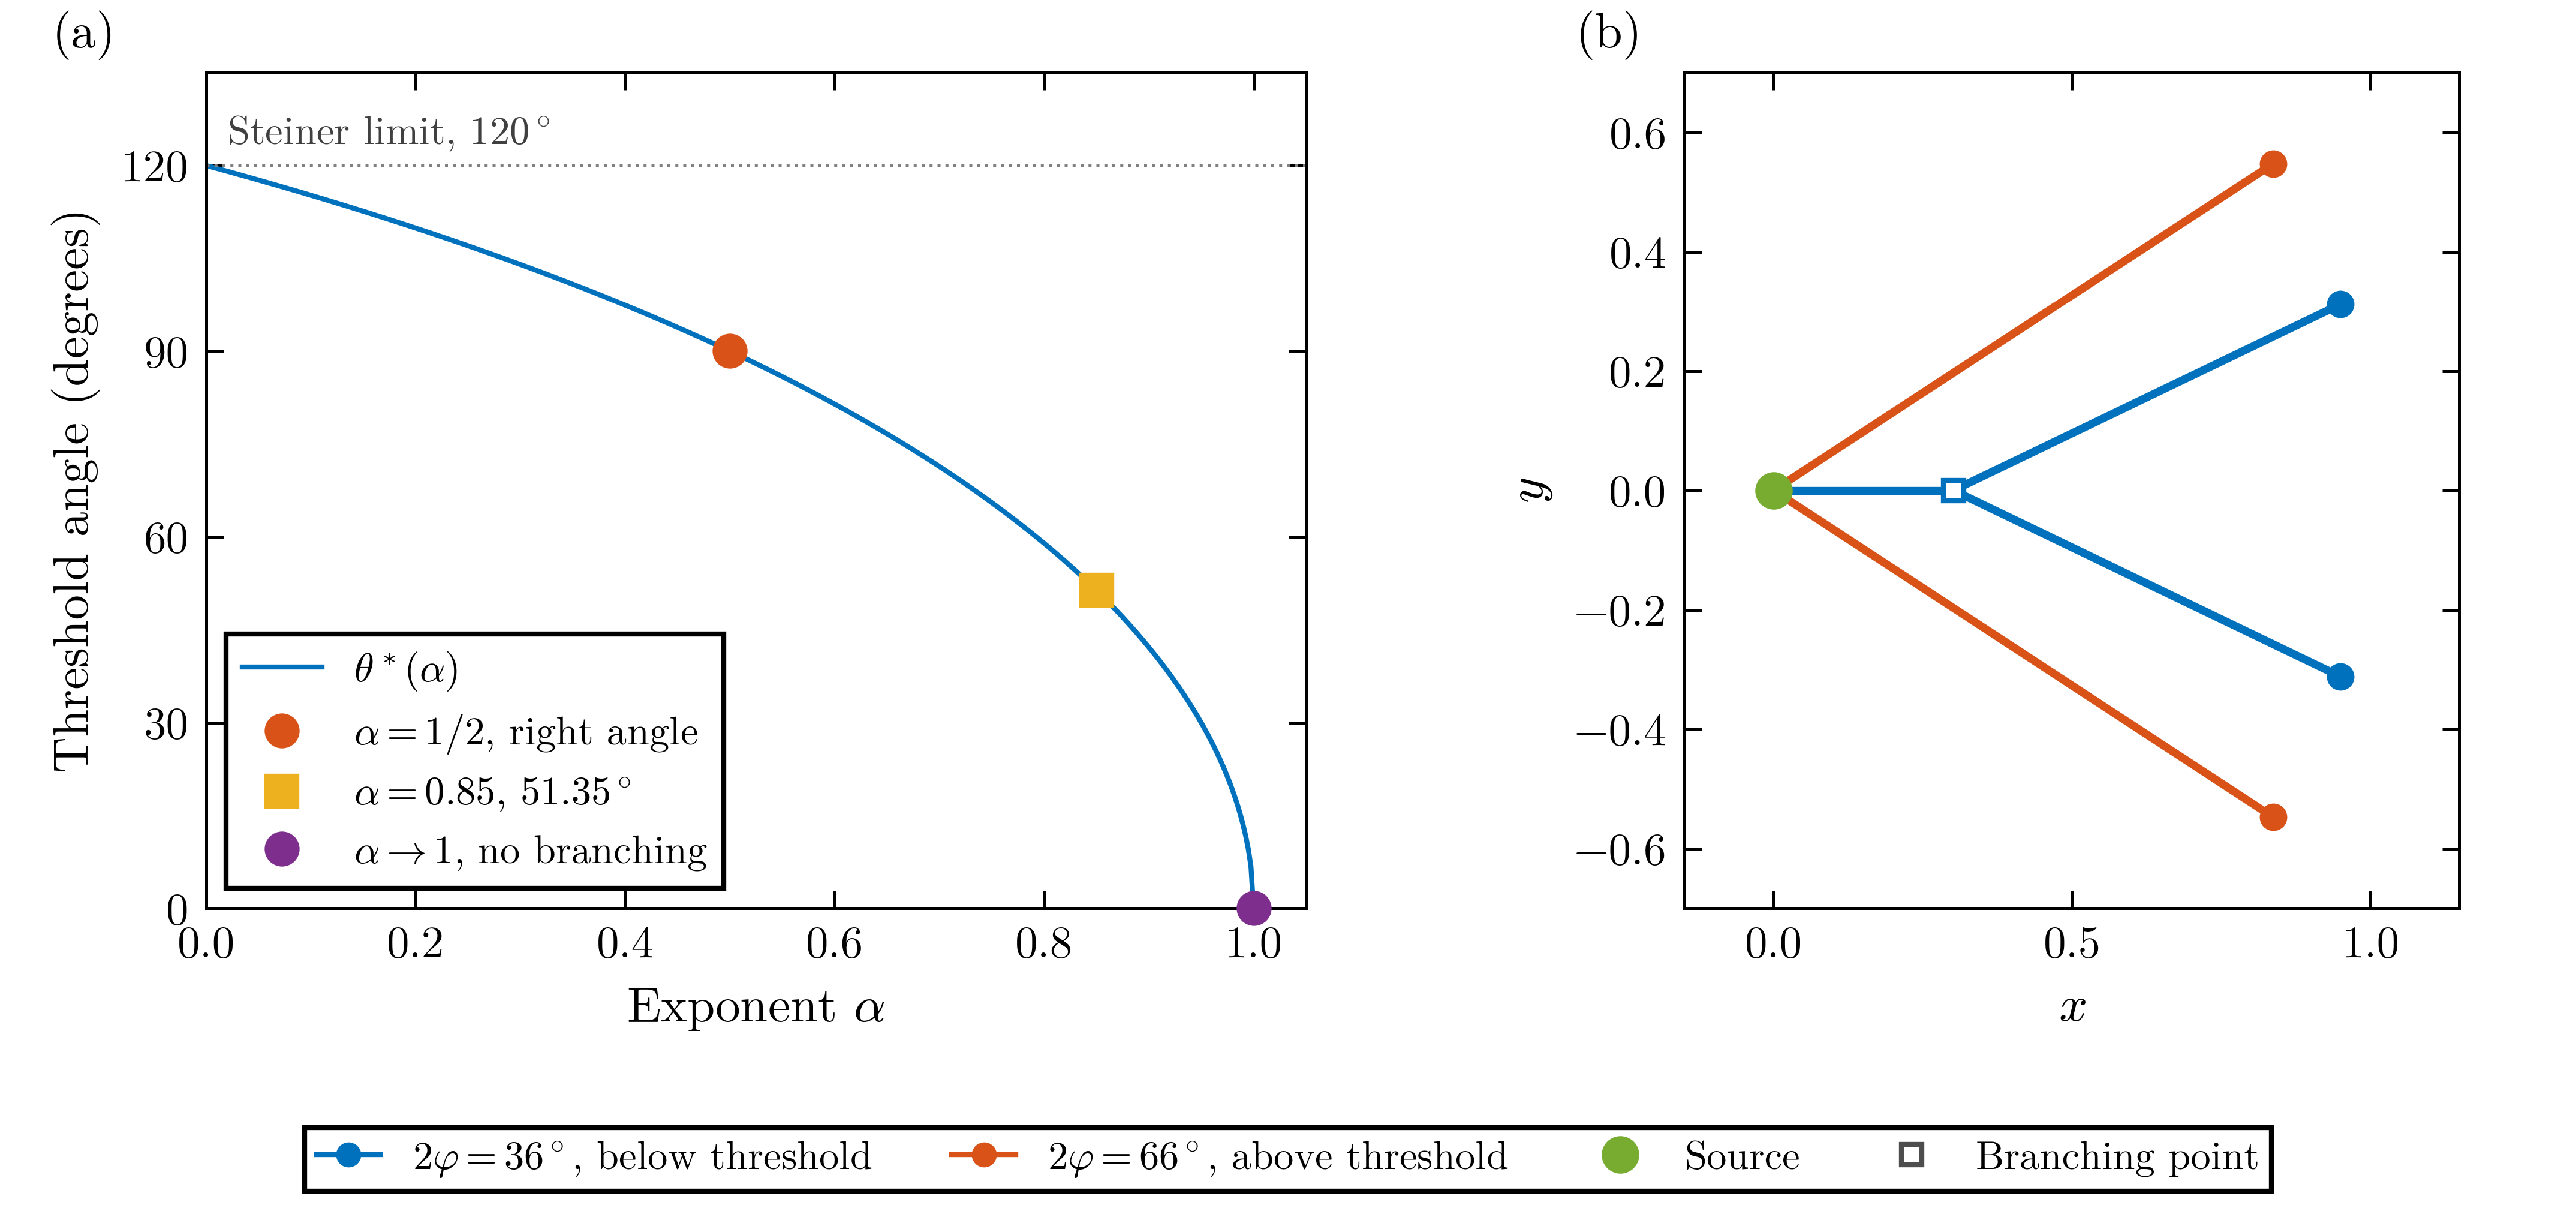

PNG identical to figures/fig_threshold_angle.png: False (differences in fonts or library versions, as in Colab, change the bytes but not the content)


In [11]:
path = RT.figure_threshold_angle(os.path.join(OUT, "figures"))
display(Image(path, width=900))
print("PNG identical to figures/fig_threshold_angle.png:", filecmp.cmp(path, os.path.join(FIG, "fig_threshold_angle.png"), shallow=False),
      "(differences in fonts or library versions, as in Colab, change the bytes but not the content)")

## 6. Six targets on a circle (Remark 2.4) and Figure 2

For $n$ unit targets equally spaced on a circle around the source, neighbors are seen under $2\pi/n$, and the pairwise criterion predicts that no pair merges when $2\pi/n\ge\theta^{\ast}(\alpha)$. For $n=6$ the threshold $60^\circ$ is crossed between $\alpha=0.75$, where $\theta^{\ast}=65.5^\circ$, and $\alpha=0.8$, where $\theta^{\ast}=59.0^\circ$: the exact solver branches at $\alpha=0.75$ and returns the star, of cost 6, at $\alpha=0.8$, $0.9$, and $0.95$. With $\theta^{\ast}(0.85)=51.35^\circ$, seven equally spaced directions are seen under $51.43^\circ$, just above the threshold.

The exact solutions at $\alpha\in\lbrace 0.5,0.75,0.8,0.9,0.95\rbrace $ are stored in `figures/theory/xia_circle_n6.json` (seven terminals, 945 topologies each). The default run recomputes $\alpha=0.75$ and $0.8$, one on each side of the threshold, in parallel; `RUN_FULL` recomputes all five.

In [12]:
stored = json.load(open(os.path.join(FIG, "theory", "xia_circle_n6.json")))["solutions"]
print(" alpha   cost       star  ties  nondegenerate branching points")
for r in stored:
    print(f" {r['alpha']:<5} {r['cost']:.6f}  {r['star']:.1f}  {r['n_optimal']:4d}  {r['nondegenerate_branching_points']}")
ck("the star costs 6 at every alpha", all(abs(r["star"] - 6.0) < 1e-12 for r in stored))
ck("branching below the threshold (alpha = 0.5, 0.75), the star above it (0.8, 0.9, 0.95)",
   all(r["cost"] < 6 - 1e-6 for r in stored if r["alpha"] < 0.8)
   and all(abs(r["cost"] - 6.0) < 1e-9 for r in stored if r["alpha"] >= 0.8))
ck("theta*(0.75) = 65.5 > 60 > theta*(0.8) = 59.0; 360/7 = 51.43 > theta*(0.85)",
   round(theta_star(0.75), 1) == 65.5 and round(theta_star(0.8), 1) == 59.0 and 360 / 7 > theta_star(0.85))

alphas = [r["alpha"] for r in stored] if RUN_FULL else [0.75, 0.8]
t0 = time.perf_counter()
fresh = RT.pmap(RT.xia_circle_solution, [(6, a) for a in alphas])
print(f"recomputed alpha = {alphas} in {time.perf_counter() - t0:.0f} s")
for r in fresh:
    old = [x for x in stored if x["alpha"] == r["alpha"]][0]
    ck(f"circle, alpha = {r['alpha']}: cost and number of tied topologies as stored",
       abs(r["cost"] - old["cost"]) <= 1e-9 * old["cost"] and r["n_optimal"] == old["n_optimal"],
       f"{r['cost']:.12f}, {r['n_optimal']} ties")

 alpha   cost       star  ties  nondegenerate branching points
 0.5   5.795555  6.0     6  3
 0.75  5.993014  6.0     6  3
 0.8   6.000000  6.0   945  0
 0.9   6.000000  6.0   945  0
 0.95  6.000000  6.0   945  0
PASS  the star costs 6 at every alpha
PASS  branching below the threshold (alpha = 0.5, 0.75), the star above it (0.8, 0.9, 0.95)
PASS  theta*(0.75) = 65.5 > 60 > theta*(0.8) = 59.0; 360/7 = 51.43 > theta*(0.85)
recomputed alpha = [0.75, 0.8] in 175 s
PASS  circle, alpha = 0.75: cost and number of tied topologies as stored  [5.993014245805, 6 ties]
PASS  circle, alpha = 0.8: cost and number of tied topologies as stored  [6.000000000000, 945 ties]


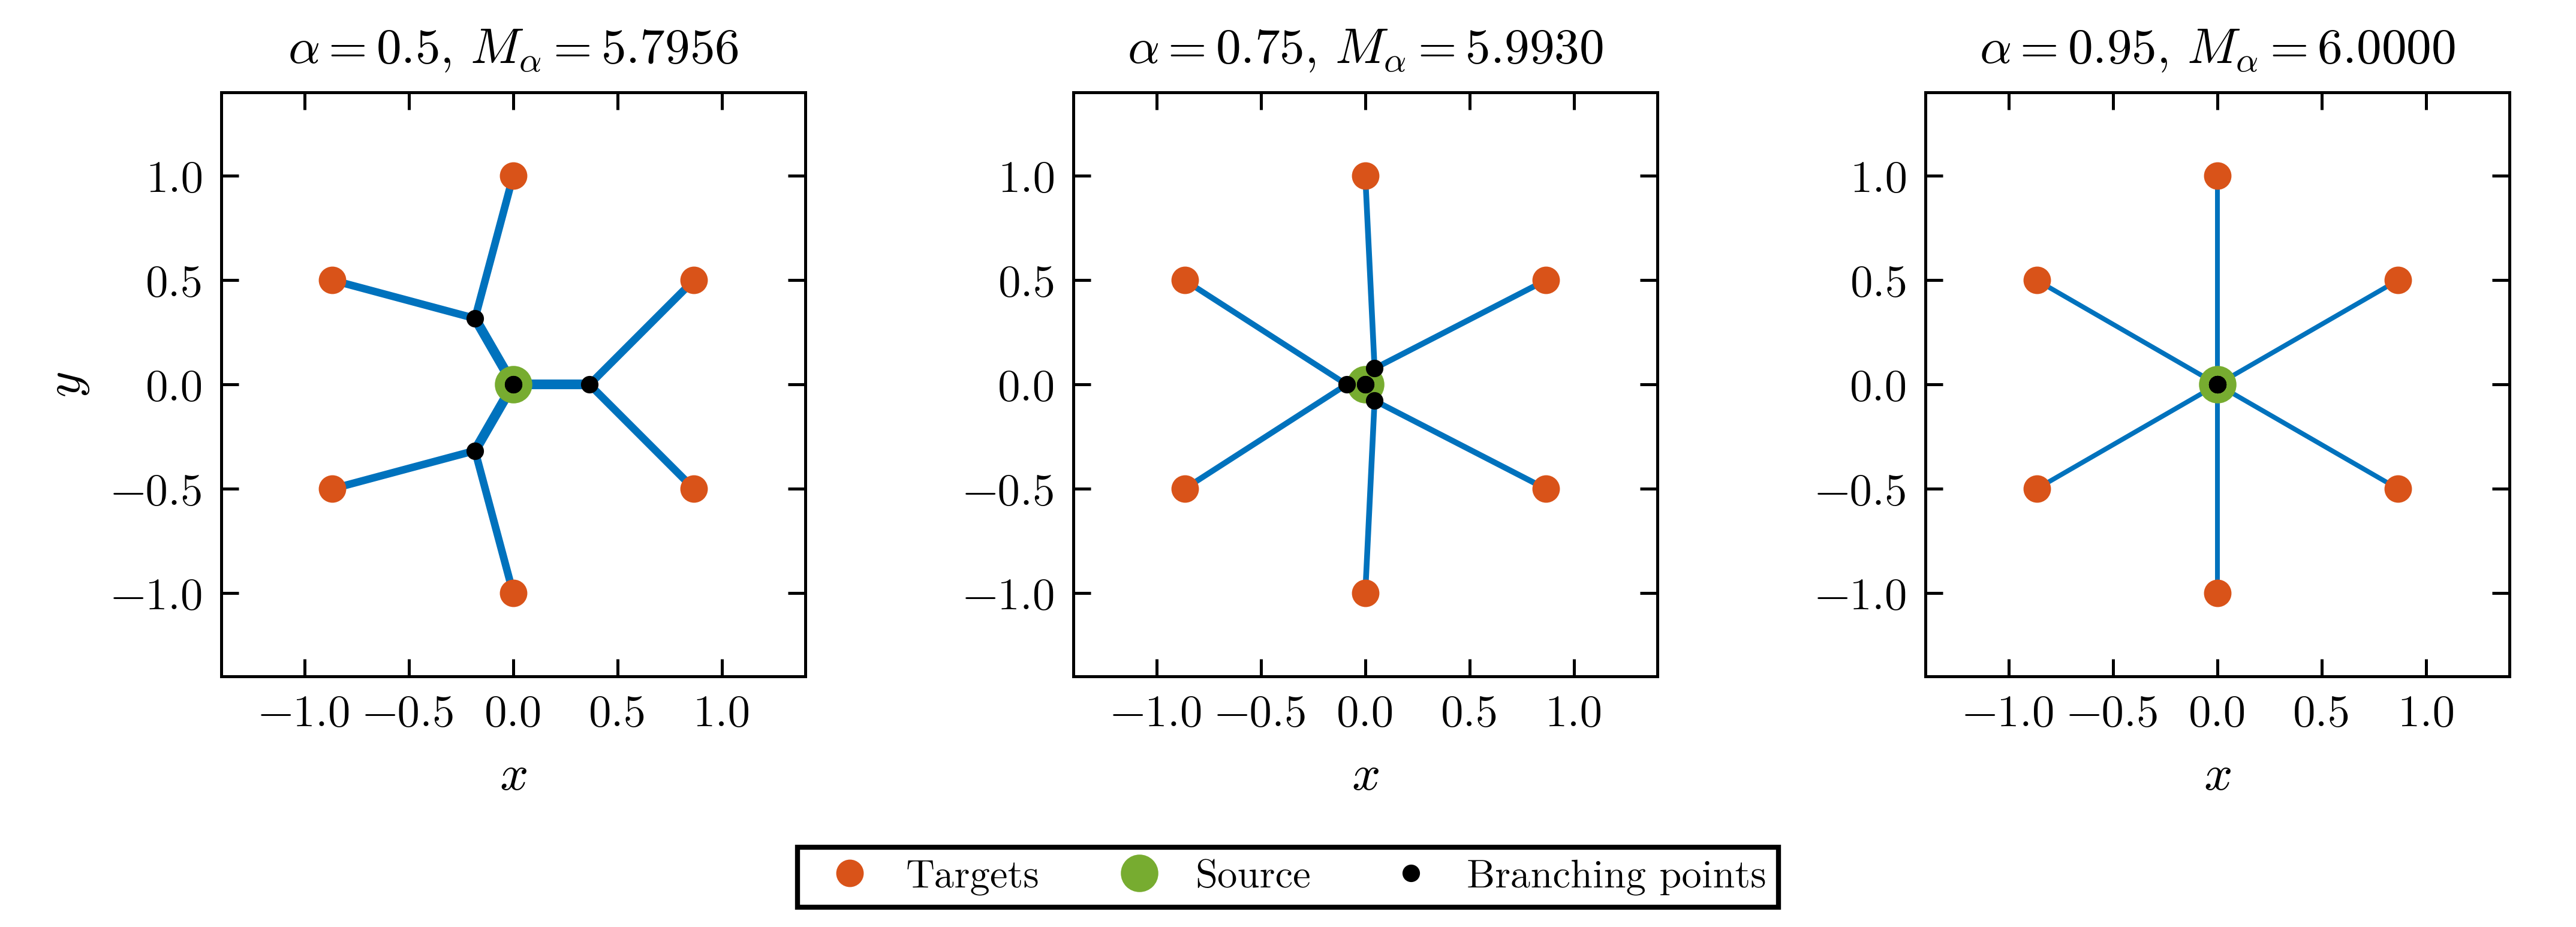

PNG identical to figures/fig_xia_circle_n6.png: False (differences in fonts or library versions, as in Colab, change the bytes but not the content)


In [13]:
path = RT.figure_xia_circle(stored, os.path.join(OUT, "figures"))
display(Image(path, width=900))
print("PNG identical to figures/fig_xia_circle_n6.png:", filecmp.cmp(path, os.path.join(FIG, "fig_xia_circle_n6.png"), shallow=False),
      "(differences in fonts or library versions, as in Colab, change the bytes but not the content)")

## 7. Cost of the exact solver (Section 4.1) and Figure 3

The time of Algorithm 1 follows the $(2k-5)!!$ law. On the laptop used for the paper (one thread) the scan took 4.6 to 6.4 ms per topology, the full solver 73 to 82 s at seven terminals and 340 to 421 s at eight; extrapolating the scan alone gives about three hours at ten terminals, two days at eleven, and two to three years at thirteen. The numbers come from `figures/exact_solver_timing.json` and `figures/scaling_measurements.json`; a fresh timing from three to five terminals follows, for comparison with this machine.

In [14]:
rows, per_topology, study = RT.scaling_rows(FIG)
scan_ms = [r["scan_ms_per_topology"] for r in study]
solve7 = [r["solve_s"] for r in study if r["terminals"] == 7]
solve8 = [r["solve_s"] for r in study if r["terminals"] == 8]
print(f"scan {min(scan_ms):.2f} to {max(scan_ms):.2f} ms per topology; full solver {min(solve7):.1f} to {max(solve7):.1f} s "
      f"at 7 terminals, {min(solve8):.1f} to {max(solve8):.1f} s at 8")
ck("stored timings: 4.6-6.4 ms per topology, 73-82 s at seven, 340-421 s at eight",
   (round(min(scan_ms), 1), round(max(scan_ms), 1)) == (4.6, 6.4) and (round(min(solve7)), round(max(solve7))) == (73, 82)
   and (round(min(solve8)), round(max(solve8))) == (340, 421))

K = np.arange(3, 21)
hours = per_topology * np.array([RC.count_full_topologies(int(k)) for k in K], dtype=float) / 3600
first = {name: int(K[np.argmax(hours > lvl)]) for name, lvl in (("hour", 1), ("day", 24), ("year", 24 * 365.25))}
print(f"median scan {1000 * per_topology:.2f} ms: {hours[K == 10][0]:.1f} h at k = 10, {hours[K == 11][0] / 24:.1f} days at "
      f"k = 11, {hours[K == 13][0] / 24 / 365.25:.1f} years at k = 13; first k above an hour, a day, a year: {first}")
ck("extrapolation: about 3 h at 10 terminals, 2 days at 11, 2 to 3 years at 13",
   round(hours[K == 10][0]) == 3 and round(hours[K == 11][0] / 24) == 2 and 2 <= hours[K == 13][0] / 24 / 365.25 <= 3
   and first == {"hour": 10, "day": 11, "year": 13})

# a fresh timing on this machine (the median of three runs on the circle instances); not compared with the paper
for k in range(3, 6):
    s, T, m = RC.instance_circle(k - 1, phase=np.pi / 2)
    times = []
    for _ in range(3):
        t0 = time.perf_counter()
        RC.solve_exhaustive(RC.terminals_of(s, T), m, 0.75)
        times.append(time.perf_counter() - t0)
    stored_k = [r[2] for r in rows if r[0] == k][0]
    print(f"k = {k}: {RC.count_full_topologies(k):3d} topologies, {np.median(times):.3f} s here, {stored_k:.3f} s stored")

scan 4.58 to 6.43 ms per topology; full solver 72.8 to 81.7 s at 7 terminals, 339.6 to 421.1 s at 8
PASS  stored timings: 4.6-6.4 ms per topology, 73-82 s at seven, 340-421 s at eight
median scan 5.79 ms: 3.3 h at k = 10, 2.3 days at k = 11, 2.5 years at k = 13; first k above an hour, a day, a year: {'hour': 10, 'day': 11, 'year': 13}
PASS  extrapolation: about 3 h at 10 terminals, 2 days at 11, 2 to 3 years at 13
k = 3:   1 topologies, 0.007 s here, 0.003 s stored
k = 4:   3 topologies, 0.106 s here, 0.069 s stored
k = 5:  15 topologies, 0.534 s here, 0.379 s stored


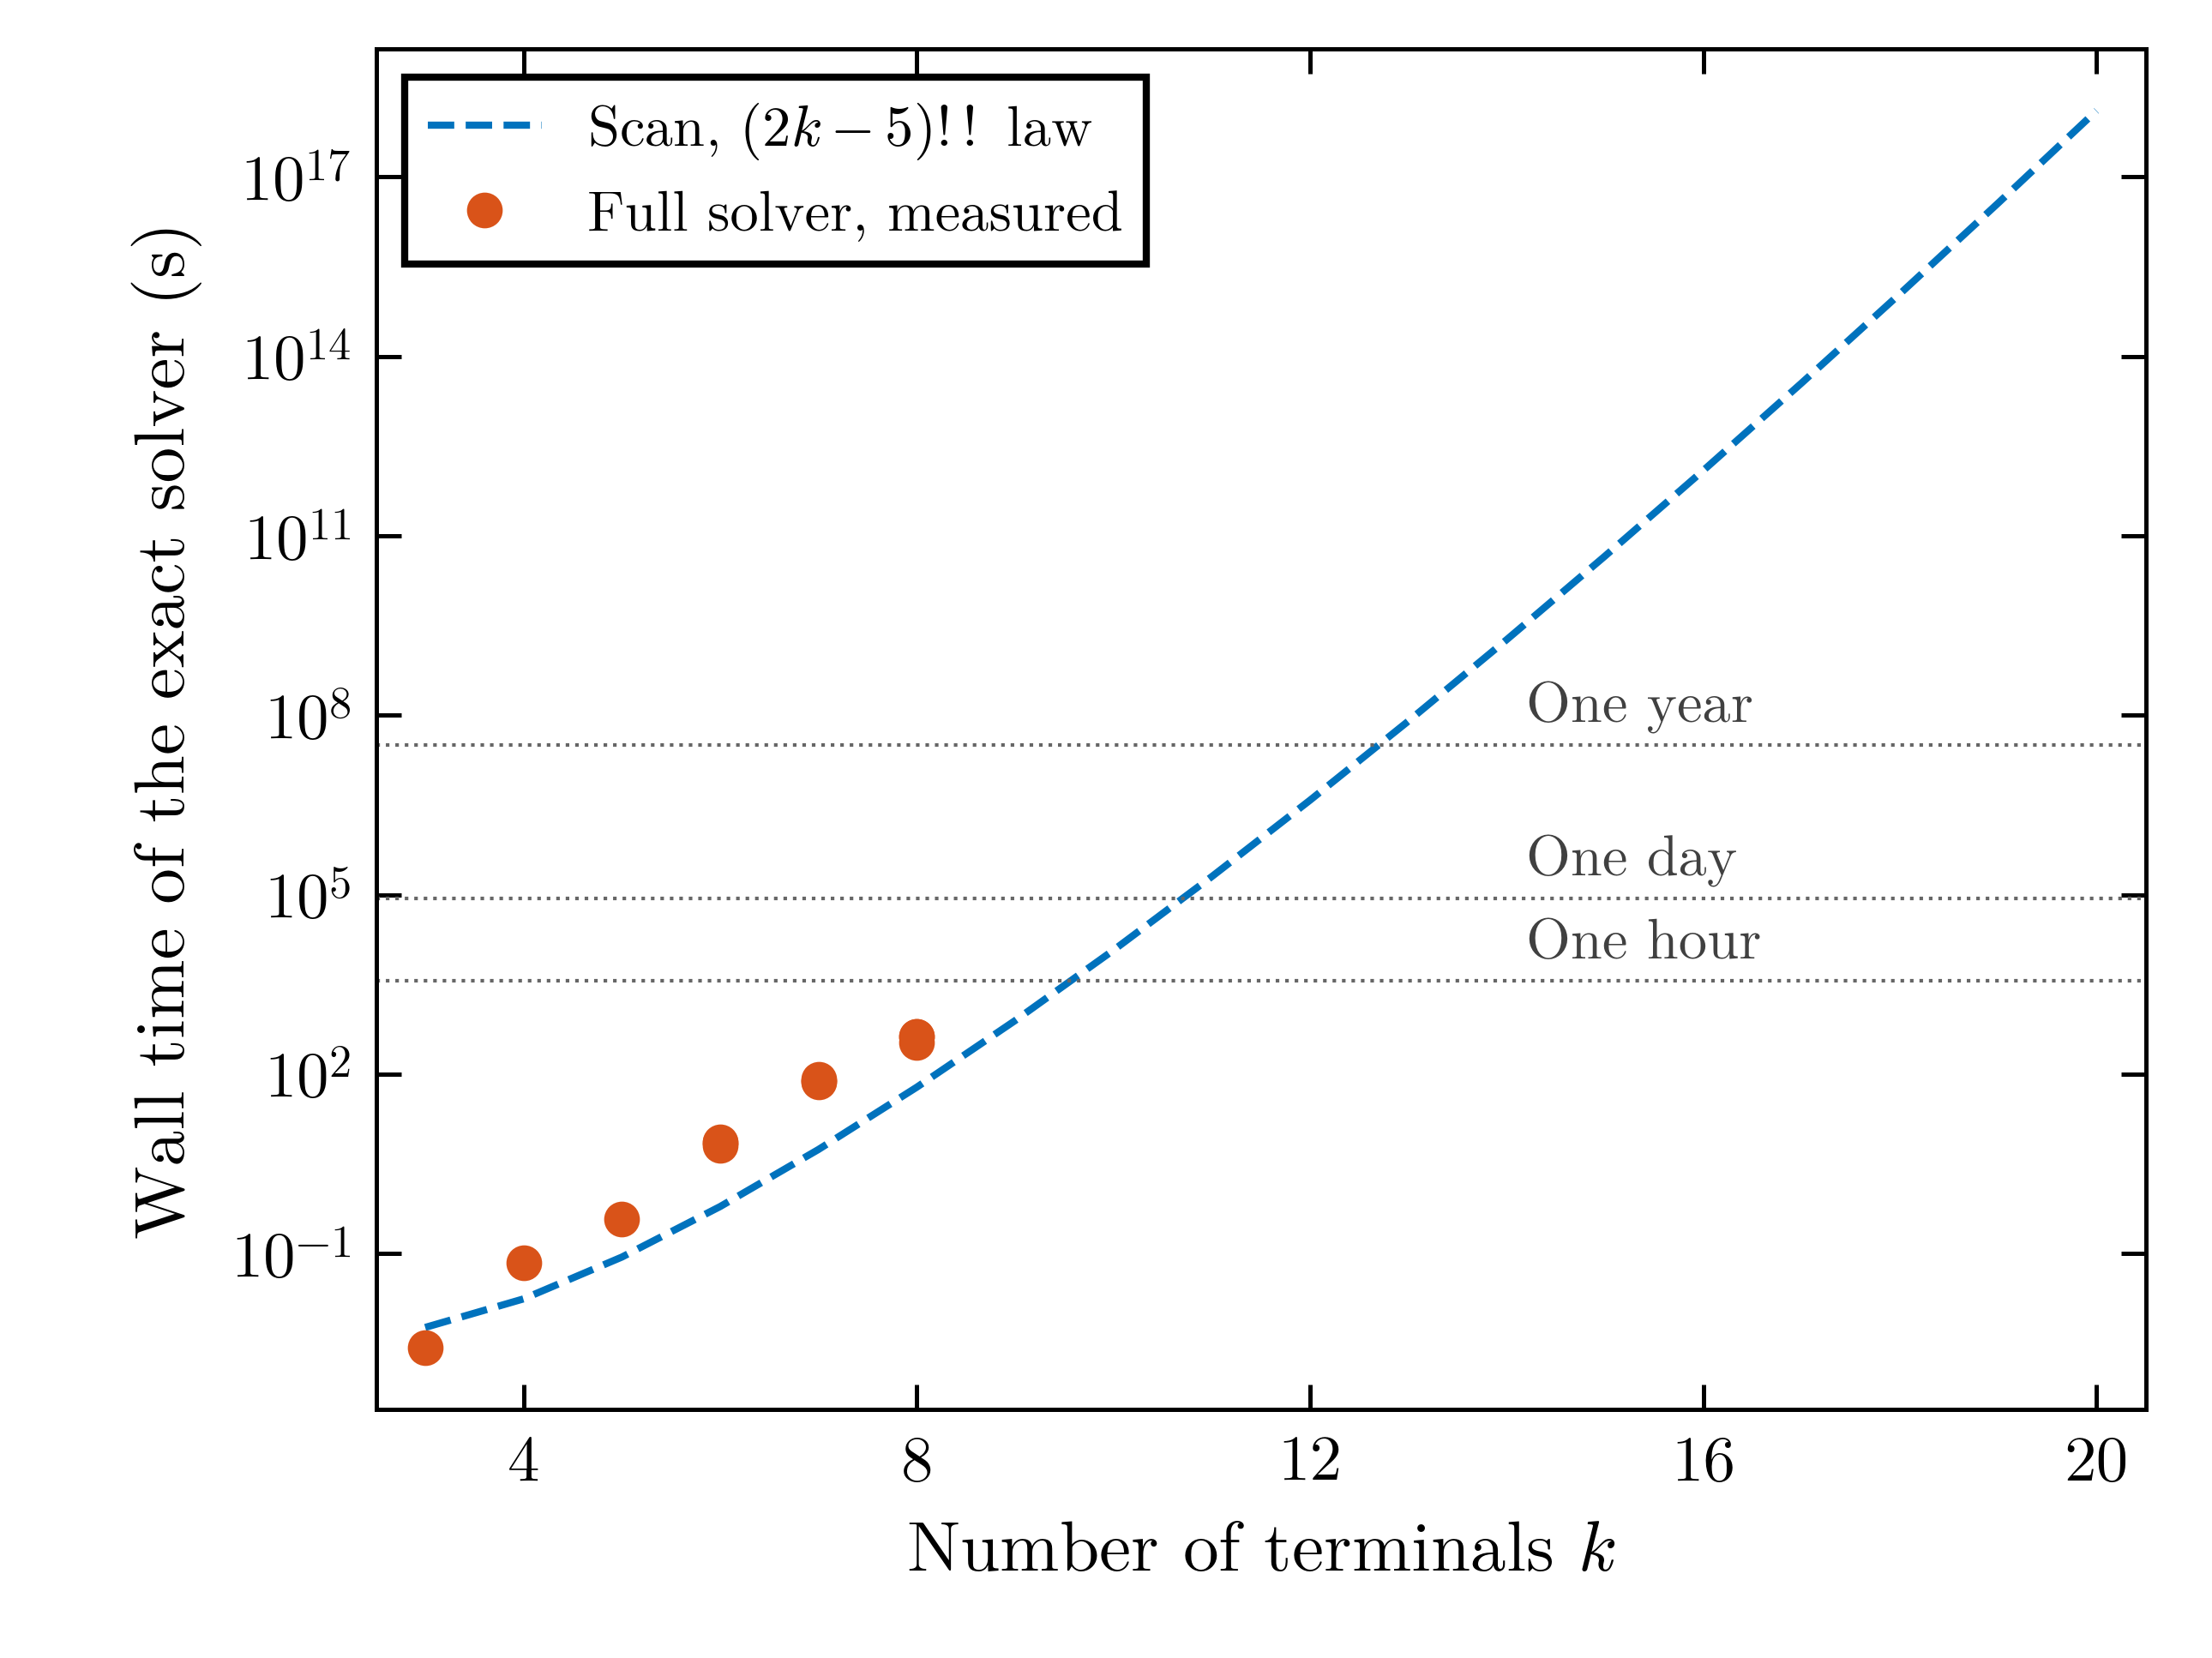

PNG identical to figures/fig_exact_scaling.png: False (differences in fonts or library versions, as in Colab, change the bytes but not the content)


In [15]:
path = RT.figure_exact_scaling(FIG, os.path.join(OUT, "figures"))
display(Image(path, width=560))
print("PNG identical to figures/fig_exact_scaling.png:", filecmp.cmp(path, os.path.join(FIG, "fig_exact_scaling.png"), shallow=False),
      "(differences in fonts or library versions, as in Colab, change the bytes but not the content)")

## 8. Summary

Every check of this notebook, and the time it took. The figures are in `colab/output/figures`.

In [16]:
all_passed = ck.summary()
print(f"notebook 1 ran in {(time.perf_counter() - T_START) / 60:.1f} minutes (RUN_FULL = {RUN_FULL})")
print("PASS" if all_passed else "FAIL")

33 of 33 checks passed
notebook 1 ran in 6.7 minutes (RUN_FULL = False)
PASS
